# Prétraitement des journaux pliés et scannés

Un journal plié en deux puis numérisé à plat présente trois défauts en amont de l'OCR et de la
segmentation FINLAM : une **ombre** le long du pli (prise pour un trait ou une bordure de colonne),
une **inclinaison différente** de chaque côté, et parfois du **texte perdu** dans le pli. Les deux
premiers se corrigent avec OpenCV sur CPU ; le troisième se signale au contrôle qualité.

Ce carnet montre la chaîne `finlam_prod.preprocess` sur une **page synthétique à vérité connue**
(on mesure ce qui est récupéré), puis sur **toute image déposée dans `data/samples/`** (une page
Gallica enregistrée depuis le navigateur, par exemple
`https://gallica.bnf.fr/iiif/ark:/12148/<ark>/f<n>/full/1600,/0/native.jpg`).

Extra requis : `pip install -e ".[image,notebooks]"`.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from finlam_prod.preprocess import (
    deskew_angle, detect_fold, normalise_illumination, preprocess_page,
)
from finlam_prod.preprocess.fold import estimate_background, _column_residual
from finlam_prod.preprocess.synthetic import folded_page

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SAMPLES = ROOT / "data/samples"
plt.rcParams["figure.dpi"] = 100


def show(before, after, report, angles, title, crop=None):
    """Avant / après / profil des colonnes du fond."""
    sl = crop or (slice(None), slice(None))
    fig, axes = plt.subplots(1, 3, figsize=(14, 6))
    axes[0].imshow(before[sl], cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(f"avant — pli {'détecté' if report.detected else 'absent'} "
                      f"x={report.x}, profondeur {report.depth:+.0f}", fontsize=9)
    axes[1].imshow(after[sl], cmap="gray", vmin=0, vmax=255)
    axes[1].set_title(f"après — angles {angles}", fontsize=9)
    for ax in axes[:2]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[2].plot(_column_residual(estimate_background(before)), color="tab:red", label="avant")
    axes[2].plot(_column_residual(estimate_background(after)), color="tab:green", label="après")
    axes[2].axhline(0, color="black", linewidth=0.5)
    axes[2].set_xlabel("colonne (px)"); axes[2].set_ylabel("fond − tendance (niveaux de gris)")
    axes[2].set_title("profil des colonnes du fond", fontsize=9); axes[2].legend(fontsize=8)
    fig.suptitle(title, fontsize=10); fig.tight_layout()
    return fig

## 1. Page synthétique : ce que la chaîne récupère

Six colonnes de « mots », moitié gauche inclinée de +1,5°, moitié droite de −1,0°, ombre de 70
niveaux de gris sur 40 px au pli, léger vignettage, bruit. On connaît la vérité : on peut mesurer.

vérité     : pli à 600 px, angles (1.5, -1.0)
détection  : FoldReport(detected=True, x=600, depth=-40.1, strength=26.57, width=48, dark=True)
correction : angles appliqués (-1.6, 1.2) (opposés des inclinaisons)
résiduel   : FoldReport(detected=False, x=605, depth=-2.9, strength=19.11, width=38, dark=True)


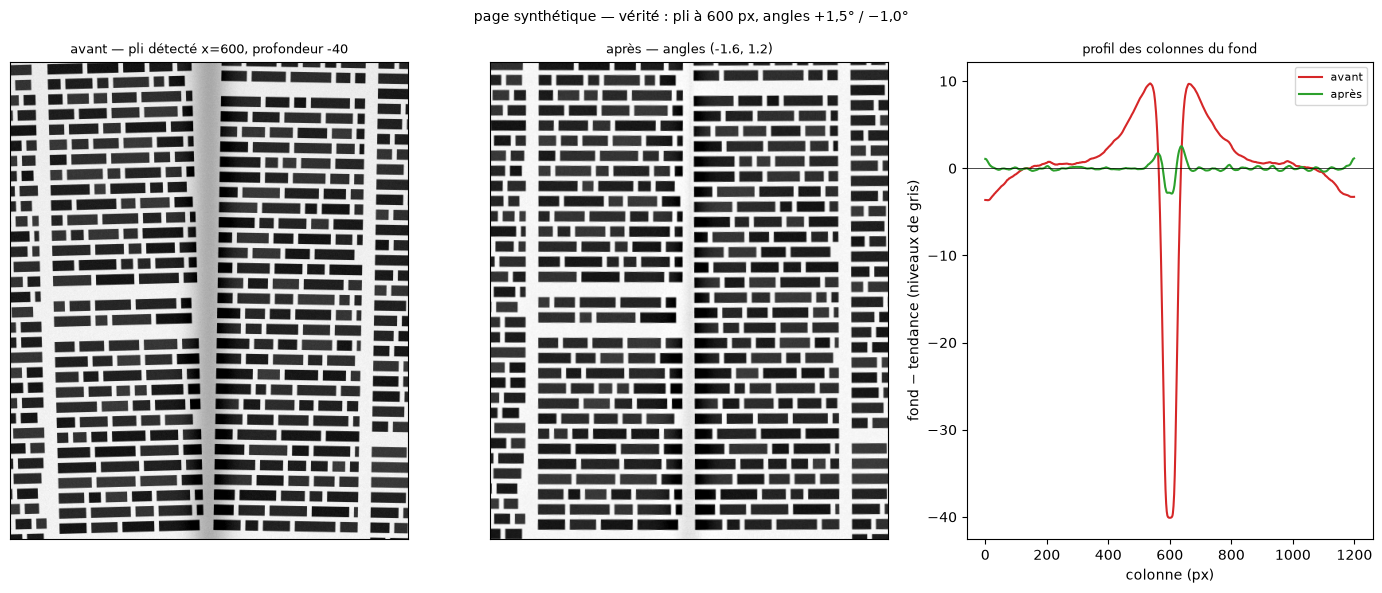

In [2]:
page = folded_page(seed=1)
result = preprocess_page(page.image)
print("vérité     : pli à", page.fold_x, "px, angles", page.angles)
print("détection  :", result.fold)
print("correction : angles appliqués", result.angles, "(opposés des inclinaisons)")
print("résiduel   :", detect_fold(result.image))
show(page.image, result.image, result.fold, result.angles,
     "page synthétique — vérité : pli à 600 px, angles +1,5° / −1,0°",
     crop=(slice(300, 900), slice(350, 850)));

Lecture : le pli est retrouvé à ±1 px, la profondeur de l'ombre passe de −40 à ±2 niveaux de
gris, les angles sont retrouvés à 0,1-0,2° près. Après correction, `detect_fold` ne déclenche
plus : c'est le critère d'arrêt qu'un contrôle qualité peut vérifier.

### Les trois étapes séparément

inclinaison estimée : gauche -1.6 ° / droite 1.2 °


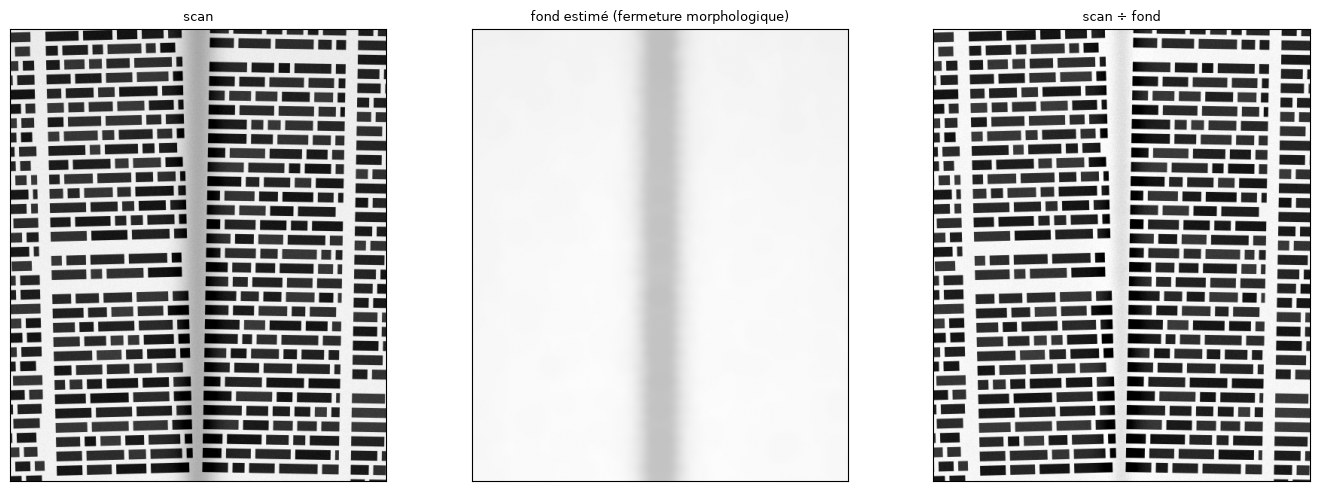

In [3]:
gray = page.image
background = estimate_background(gray)
flat = normalise_illumination(gray)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, img, t in zip(axes, (gray, background, flat),
                      ("scan", "fond estimé (fermeture morphologique)", "scan ÷ fond")):
    ax.imshow(img[300:900, 350:850], cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

left, right = flat[:, :result.fold.x], flat[:, result.fold.x:]
print("inclinaison estimée : gauche", deskew_angle(left[:, :-result.fold.width]),
      "° / droite", deskew_angle(right[:, result.fold.width:]), "°")

### Robustesse : profondeur de l'ombre et angles

Jusqu'où la détection tient-elle ? On fait varier l'ombre (une ombre faible ne doit pas déclencher
à tort, une ombre marquée doit être vue) et les angles.

In [4]:
rows = []
for depth in (0, 5, 10, 20, 40, 70, 100):
    for angles in ((0.0, 0.0), (1.5, -1.0), (-2.5, 2.0)):
        p = folded_page(shadow_depth=depth, angles=angles, seed=7)
        r = preprocess_page(p.image)
        rows.append({"ombre": depth, "angles": angles, "pli détecté": r.fold.detected,
                     "x": r.fold.x, "profondeur": r.fold.depth,
                     "erreur angle max": max(abs(a + b) for a, b in zip(r.angles, angles))
                     if len(r.angles) == 2 else abs(r.angles[0]) + max(map(abs, angles))})
pd.DataFrame(rows)

,ombre,angles,pli détecté,x,profondeur,erreur angle max
0,0,"(0.0, 0.0)",False,793,1.0,0.0
1,0,"(1.5, -1.0)",False,789,0.9,3.1
2,0,"(-2.5, 2.0)",False,570,0.9,4.5
3,5,"(0.0, 0.0)",False,604,-2.5,0.0
4,5,"(1.5, -1.0)",False,603,-2.4,3.1
5,5,"(-2.5, 2.0)",False,601,-2.4,4.5
6,10,"(0.0, 0.0)",False,600,-5.8,0.0
7,10,"(1.5, -1.0)",False,599,-5.6,3.1
8,10,"(-2.5, 2.0)",False,600,-5.8,4.5
9,20,"(0.0, 0.0)",True,600,-12.2,0.0


Lecture : sans ombre ou avec une ombre très faible, pas de détection — la page est traitée entière
avec un seul angle, d'où une « erreur » qui n'est que l'écart entre les deux moitiés, qu'on ne
peut pas corriger sans savoir où couper. Dès une ombre d'une vingtaine de niveaux de gris
(profondeur mesurée sur le fond ≥ `min_depth=10`), le pli est vu et chaque moitié est redressée à
0,1° près. En dessous, une ombre aussi légère ne gêne de toute façon pas l'OCR.

## 2. Vraies pages de *La Liberté*

`finlam-prod download --dataset la-liberte` a déposé des pages JPEG (1 736 × 2 500) dans
`data/cache/images_la_liberte/`. Ce sont des scans **propres** : pas d'ombre de pli. On n'a pas
de page à la fois pliée et à plat ; on **simule donc le pli sur la vraie page**
(`simulate_fold` : mêmes inclinaisons par moitié, ombre, vignettage, bruit que la page
synthétique) — texte, mise en page, gravures et bruit de scan sont réels, le défaut est connu.

40 pages réelles


pli simulé à 874 px ; détecté : FoldReport(detected=True, x=873, depth=-37.4, strength=15.62, width=69, dark=True)
angles appliqués : (-0.9, 1.5)


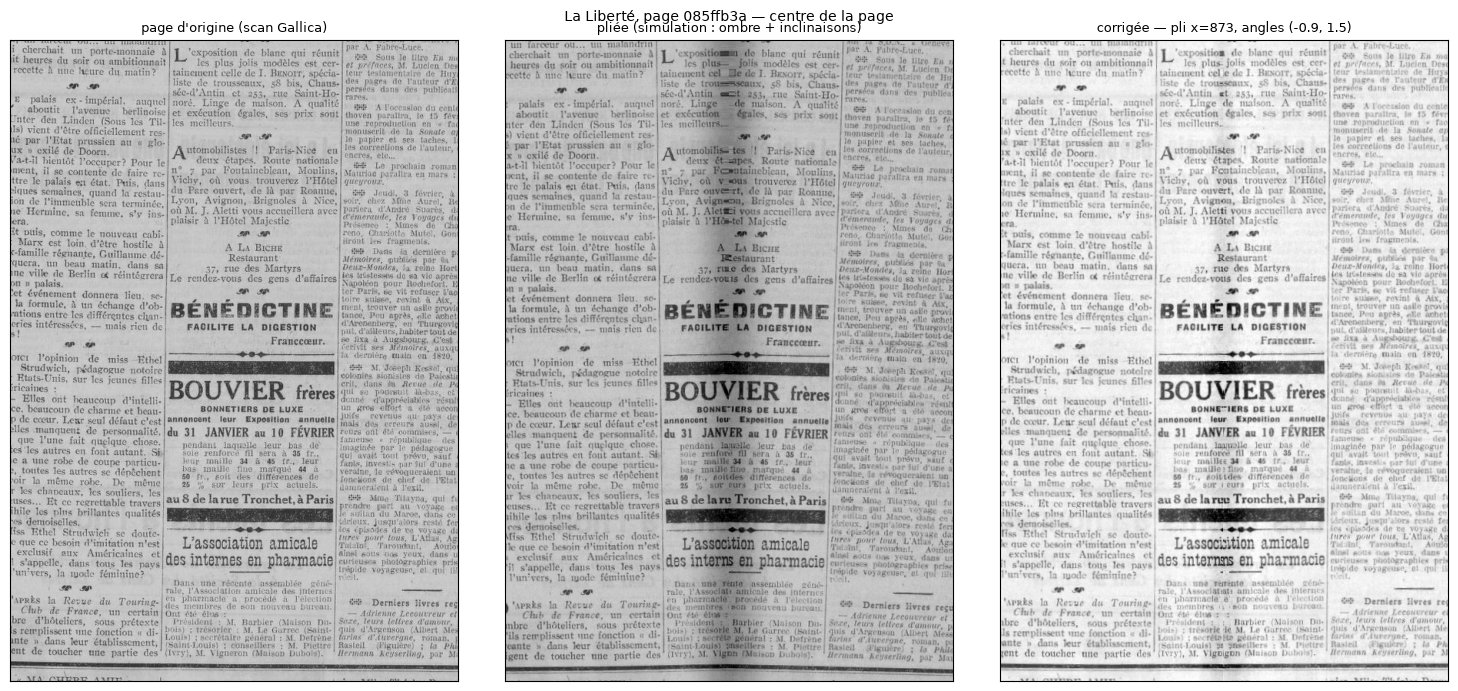

In [5]:
from finlam_prod.preprocess.synthetic import simulate_fold

IMAGES = sorted((ROOT / "data/cache/images_la_liberte").glob("*.jpg"))
print(len(IMAGES), "pages réelles")


def read_gray(path):
    data = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if data is None:
        raise FileNotFoundError(path)
    return data


real = read_gray(IMAGES[0])
folded = simulate_fold(real, angles=(1.5, -1.0), shadow_depth=60, seed=0)
result = preprocess_page(folded.image)
h, w = real.shape
crop = (slice(h // 3, 2 * h // 3), slice(w // 3, 2 * w // 3))
print("pli simulé à", folded.fold_x, "px ; détecté :", result.fold)
print("angles appliqués :", result.angles)
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, img, title in zip(
    axes,
    (real, folded.image, result.image),
    ("page d'origine (scan Gallica)", "pliée (simulation : ombre + inclinaisons)",
     f"corrigée — pli x={result.fold.x}, angles {result.angles}"),
):
    ax.imshow(img[crop], cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"La Liberté, page {IMAGES[0].stem[:8]} — centre de la page", fontsize=10)
fig.tight_layout();

**A-t-on perdu du texte au pli ?** Non. Le redressement est un `remap` sur l'image entière : près
du pli, chaque côté redressé reprend ses pixels de l'autre côté de la coupe, là où le texte se
trouve réellement ; seules les marges extérieures reçoivent du blanc. On le vérifie en comparant la
densité d'encre dans une bande de 60 px autour du pli, entre la page d'origine (passée par la même
normalisation d'éclairage, qui éclaircit uniformément le gris du papier journal) et la page
corrigée.

origine                          encre (pixels < 128) dans la bande du pli : 0.098
origine, éclairage normalisé     encre (pixels < 128) dans la bande du pli : 0.057
pliée                            encre (pixels < 128) dans la bande du pli : 0.368
corrigée                         encre (pixels < 128) dans la bande du pli : 0.062


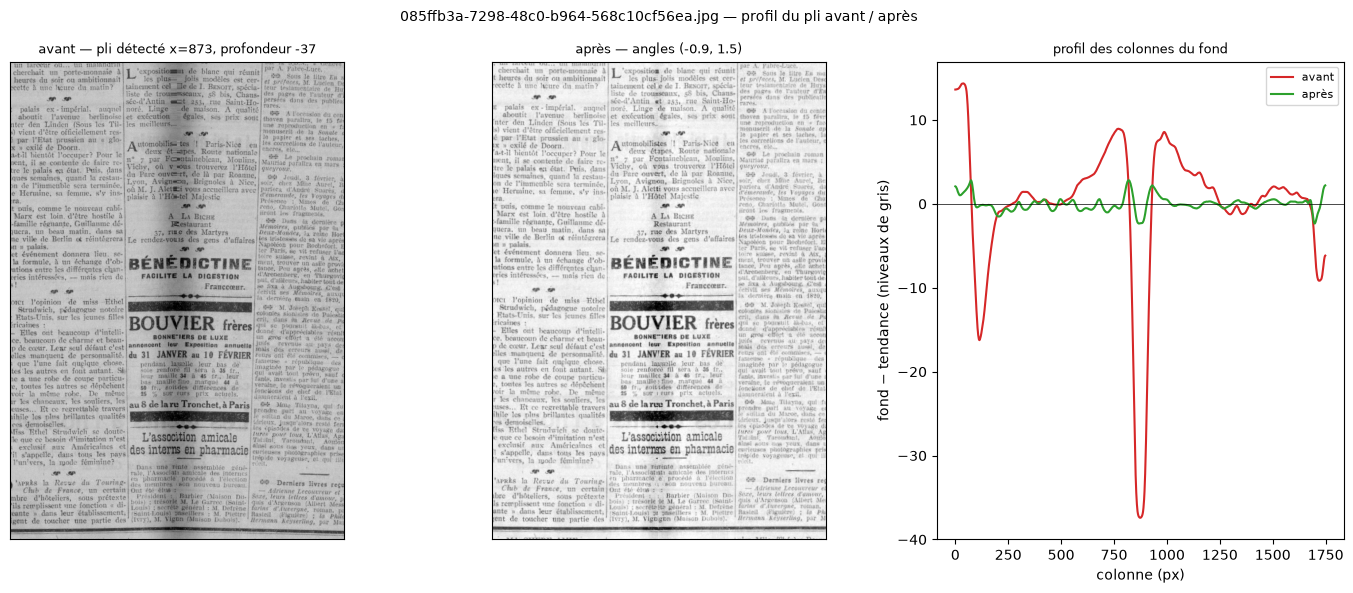

In [6]:
band = slice(folded.fold_x - 30, folded.fold_x + 30)
origin_norm = normalise_illumination(real)
for name, img in (("origine", real), ("origine, éclairage normalisé", origin_norm),
                  ("pliée", folded.image), ("corrigée", result.image)):
    ink = (img[:, band] < 128).mean()
    print(f"{name:32s} encre (pixels < 128) dans la bande du pli : {ink:.3f}")
show(folded.image, result.image, result.fold, result.angles,
     f"{IMAGES[0].name} — profil du pli avant / après", crop=crop);

Sur une vraie page, la vérité des angles n'est pas « +1,5° / −1,0° » : le scan d'origine a déjà
sa propre inclinaison (quelques dixièmes de degré, souvent différente à gauche et à droite). Le
bon critère est donc **l'horizontalité après correction** : `deskew_angle` sur chaque moitié
corrigée doit rendre ~0. On le mesure sur toutes les pages, avec des inclinaisons variées.

In [7]:
rows = []
cases = ((1.5, -1.0), (-2.0, 0.5), (0.8, 1.6), (0.0, 0.0))
for i, path in enumerate(IMAGES):
    real = read_gray(path)
    angles = cases[i % len(cases)]
    folded = simulate_fold(real, angles=angles, shadow_depth=60, seed=i)
    r = preprocess_page(folded.image)
    x = r.fold.x if r.fold.detected else folded.fold_x
    residual = (deskew_angle(r.image[:, :x]), deskew_angle(r.image[:, x:]))
    rows.append({"page": path.stem[:8], "angles simulés": angles,
                 "pli détecté": r.fold.detected,
                 "erreur position (px)": abs(r.fold.x - folded.fold_x),
                 "résiduel gauche (°)": residual[0], "résiduel droite (°)": residual[1],
                 "pli après": detect_fold(r.image).detected})
table = pd.DataFrame(rows)
abs_res = table[["résiduel gauche (°)", "résiduel droite (°)"]].abs().stack()
print("pli détecté :", int(table["pli détecté"].sum()), "/", len(table),
      "| position : médiane", table["erreur position (px)"].median(), "px, max",
      table["erreur position (px)"].max(), "px")
print("résiduel |angle| après correction : médiane", abs_res.median(), "°, 90e pct",
      round(abs_res.quantile(0.9), 2), "°, max", abs_res.max(), "°")
print("pli encore détecté après :", int(table["pli après"].sum()))
table

pli détecté : 40 / 40 | position : médiane 1.0 px, max 12 px
résiduel |angle| après correction : médiane 0.0 °, 90e pct 0.1 °, max 0.5 °
pli encore détecté après : 0


,page,angles simulés,pli détecté,erreur position (px),résiduel gauche (°),résiduel droite (°),pli après
0,085ffb3a,"(1.5, -1.0)",True,1,0.1,0.0,False
1,17c1eb0c,"(-2.0, 0.5)",True,1,0.1,0.0,False
2,1e8d16df,"(0.8, 1.6)",True,0,0.0,0.1,False
3,28d0b5d8,"(0.0, 0.0)",True,4,0.5,0.0,False
4,352cb719,"(1.5, -1.0)",True,2,0.0,0.1,False
5,37214212,"(-2.0, 0.5)",True,3,0.0,0.0,False
6,388f89ff,"(0.8, 1.6)",True,1,0.0,0.0,False
7,3c2084df,"(0.0, 0.0)",True,1,0.0,0.0,False
8,44d80c1e,"(1.5, -1.0)",True,2,0.0,0.1,False
9,44fac384,"(-2.0, 0.5)",True,2,0.0,0.0,False


## 3. Pas de fausse alerte : les 40 pages réelles, telles quelles

Un prétraitement qui « corrige » une page qui n'a rien ne doit rien faire. On passe les scans
d'origine, sans pli simulé : la détection doit rester silencieuse.

In [8]:
clean_rows = []
for path in IMAGES:
    f = detect_fold(read_gray(path))
    clean_rows.append({"page": path.stem[:8], "détecté": f.detected, "profondeur": f.depth,
                       "force": f.strength})
clean_table = pd.DataFrame(clean_rows)
print("fausses détections :", int(clean_table["détecté"].sum()), "/", len(clean_table),
      "| profondeur max observée :", clean_table["profondeur"].abs().max(),
      "niveaux de gris (seuil : 10)")
clean_table.describe().loc[["mean", "min", "max"]]

fausses détections : 0 / 40 | profondeur max observée : 8.0 niveaux de gris (seuil : 10)


,profondeur,force
mean,-1.17,2.032
min,-8.00,1.250
max,4.30,4.960


## 4. Les pires cas réels du split test (433 pages), sans simulation

`scripts/find_worst_pages.py` passe les 433 pages du split test au détecteur avec des seuils
relâchés et à l'estimateur d'inclinaison, écrit `data/samples/worst_pages.csv` et copie les pires
pages dans `data/samples/`. Verdict : **aucune page pliée dans La Liberté** — le jeu a été
constitué pour l'annotation, à partir de bons scans. Ce qui remonte, c'est autre chose, et c'est
instructif.

433 pages mesurées


ombre ≥ 10 niveaux : 0 page(s) ; bande claire ≥ 10 : 2 page(s) ; inclinaison ≥ 1° : 31 page(s)


,index,page_id,fold_depth,fold_strength,fold_x,fold_detected,skew_deg,dark_left_border
0,400,row400,12.3,7.09,365,True,0.1,0.000
1,339,row339,10.5,2.69,1008,False,0.2,0.000
2,125,row125,-9.9,5.68,354,False,1.1,0.048
3,5,row5,-8.0,3.21,843,False,-0.1,0.021
4,30,row30,-7.9,4.94,1303,False,0.6,0.000
5,376,row376,-7.9,2.98,584,False,0.6,0.000
6,261,row261,-7.9,3.16,546,True,0.4,0.001
7,192,row192,-7.8,3.38,1011,False,-0.3,0.009


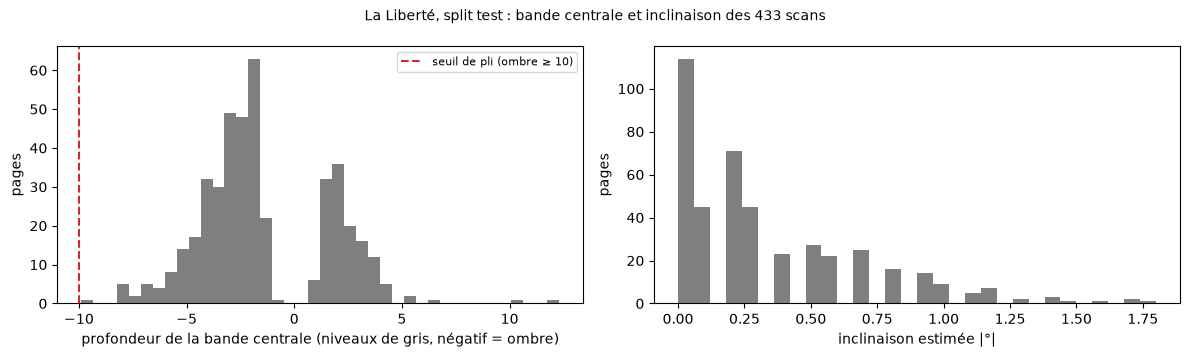

In [9]:
worst = pd.read_csv(SAMPLES / "worst_pages.csv")
print(len(worst), "pages mesurées")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(worst["fold_depth"], bins=40, color="tab:gray")
axes[0].axvline(-10, color="tab:red", linestyle="--", label="seuil de pli (ombre ≥ 10)")
axes[0].set_xlabel("profondeur de la bande centrale (niveaux de gris, négatif = ombre)")
axes[0].set_ylabel("pages"); axes[0].legend(fontsize=8)
axes[1].hist(worst["skew_deg"].abs(), bins=30, color="tab:gray")
axes[1].set_xlabel("inclinaison estimée |°|"); axes[1].set_ylabel("pages")
fig.suptitle("La Liberté, split test : bande centrale et inclinaison des 433 scans", fontsize=10)
fig.tight_layout()
print("ombre ≥ 10 niveaux :", int((worst["fold_depth"] <= -10).sum()), "page(s) ;",
      "bande claire ≥ 10 :", int((worst["fold_depth"] >= 10).sum()), "page(s) ;",
      "inclinaison ≥ 1° :", int((worst["skew_deg"].abs() >= 1).sum()), "page(s)")
worst.head(8)

Les deux pages à bande *claire* marquée (`row400`, `row339`) sont des **pleines pages de
publicité** (Citroën) : la « bande » est une colonne vide de la mise en page. La première
déclenchait une détection avec les seuils initiaux — une vraie fausse alerte, que les 40 premières
pages n'avaient pas montrée. Un pli est une **ombre** ; une bande claire n'est désormais retenue
qu'avec `allow_bright=True`. Les pages à ombre de 8-10 niveaux (`row125`, `row5`, `row261`) sont
des ombres de reliure ou de bord, sous le seuil, sans effet. Le vrai défaut de ce jeu, c'est
**l'inclinaison** : jusqu'à 1,8° (`row57`), que le pipeline corrige sans pli.

worst_test_12.3_row400.jpg: pleine page de publicité (bande claire, pas un pli)
   pli : FoldReport(detected=False, x=365, depth=12.3, strength=7.09, width=146, dark=False) | angle : (0.1,) | résiduel : -0.6 °


skew_test_1.8_row57.jpg: page la plus inclinée du split test
   pli : FoldReport(detected=False, x=863, depth=-1.8, strength=1.45, width=42, dark=True) | angle : (1.6,) | résiduel : 0.2 °


worst_test_09.9_row125.jpg: ombre de bord + inclinaison
   pli : FoldReport(detected=False, x=354, depth=-9.9, strength=5.71, width=61, dark=True) | angle : (0.0,) | résiduel : 0.0 °


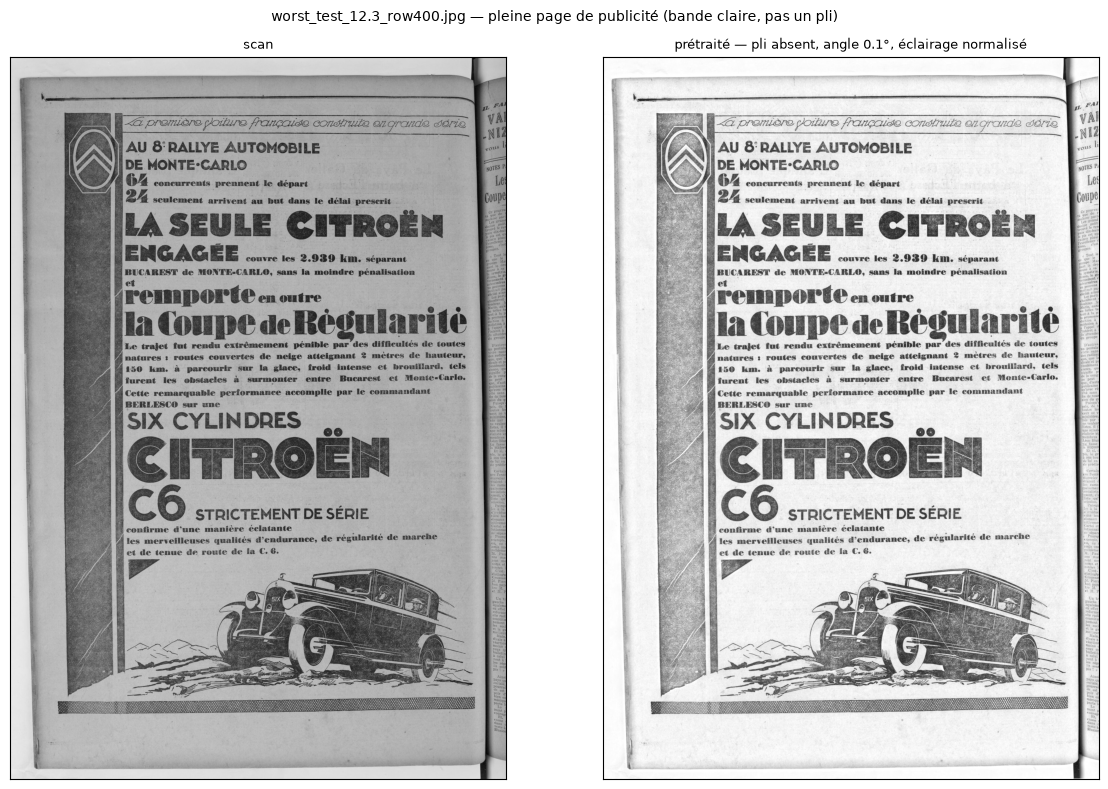

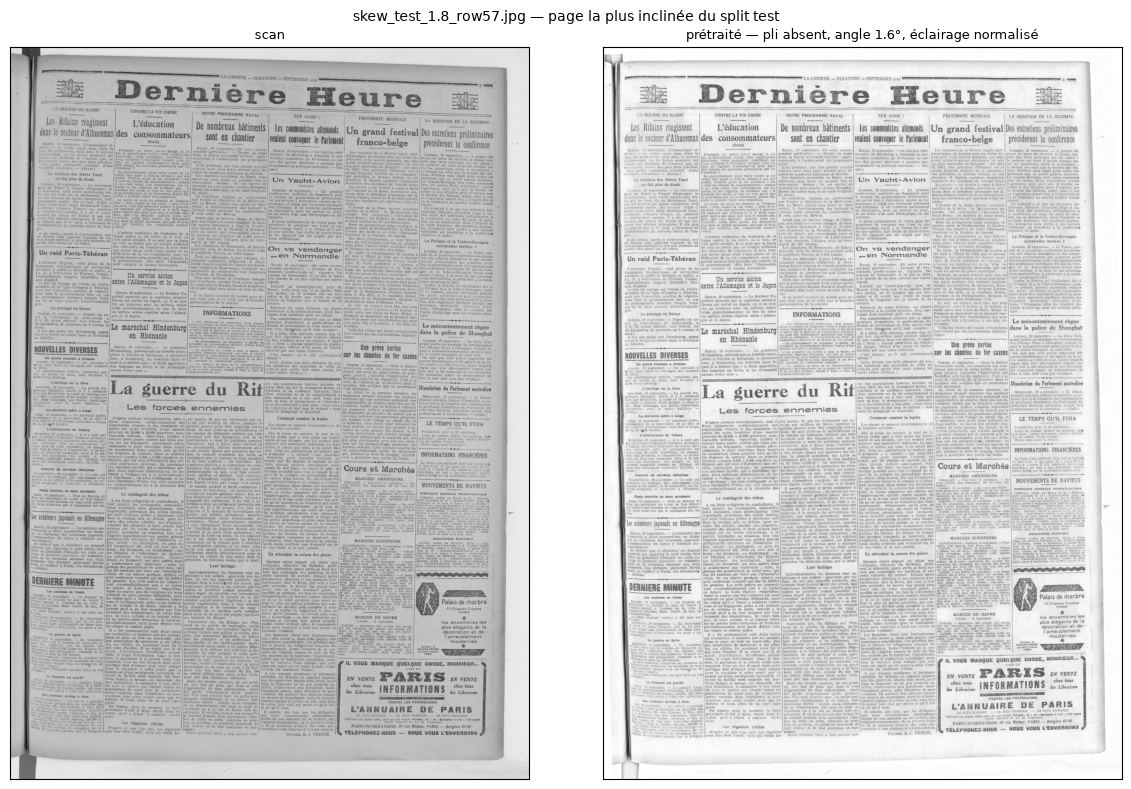

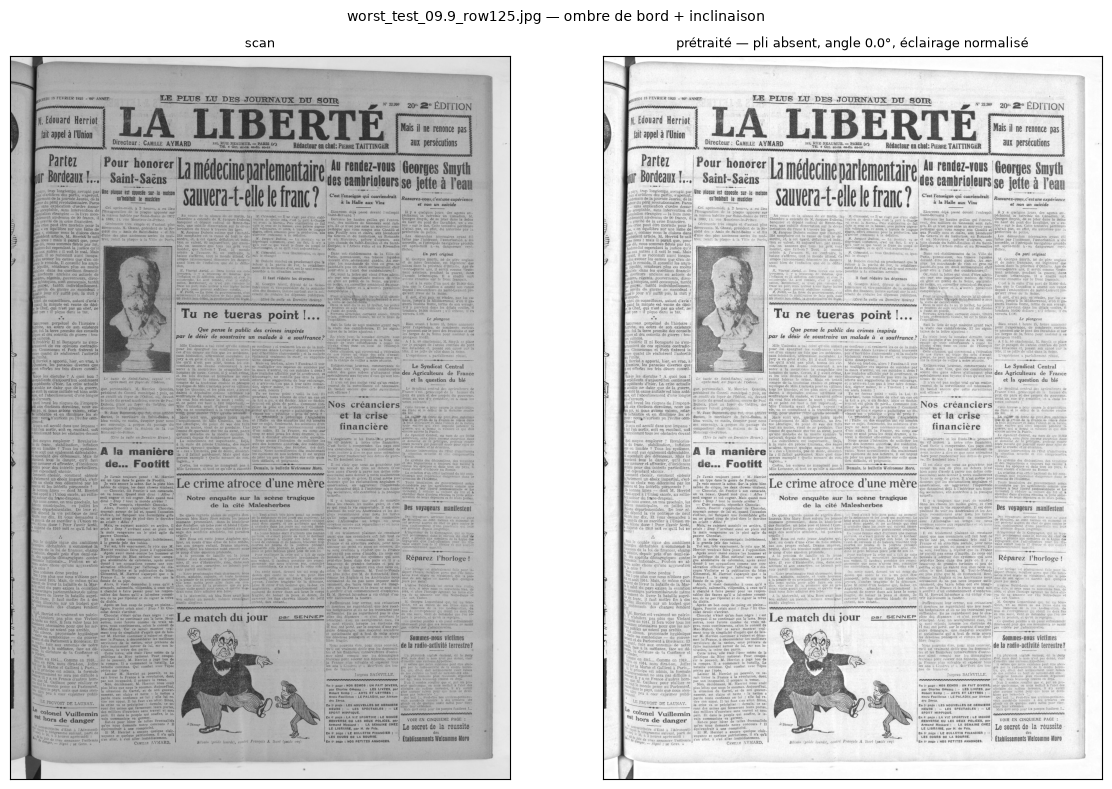

In [10]:
def pick(prefix):
    found = sorted(SAMPLES.glob(prefix + "*.jpg"))
    return found[0] if found else None

cases = [("pleine page de publicité (bande claire, pas un pli)", pick("worst_test_12.3")),
         ("page la plus inclinée du split test", pick("skew_test_")),
         ("ombre de bord + inclinaison", pick("worst_test_09.9"))]
for label, path in cases:
    if path is None:
        continue
    gray = read_gray(path)
    r = preprocess_page(gray)
    print(f"{path.name}: {label}")
    print("   pli :", r.fold, "| angle :", r.angles, "| résiduel :", deskew_angle(r.image), "°")
    h, w = gray.shape
    fig, axes = plt.subplots(1, 2, figsize=(12, 8))
    axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[0].set_title("scan", fontsize=9)
    axes[1].imshow(r.image, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title(f"prétraité — pli {'détecté' if r.fold.detected else 'absent'}, "
                      f"angle {r.angles[0]}°, éclairage normalisé", fontsize=9)
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{path.name} — {label}", fontsize=10)
    fig.tight_layout()

Deux lectures. (1) `row125` : le script mesurait 1,1° sur l'image **brute**, la chaîne trouve 0°
après normalisation de l'éclairage — l'ombre de bord sombre biaisait l'estimateur ; c'est
pourquoi la normalisation précède toujours le redressement. (2) `row400` : sur une pleine page de
publicité, pauvre en lignes de texte, l'estimateur d'angle est moins fiable (résiduel 0,6°) ;
en production, on ne redresse que si la page contient assez de lignes (critère à ajouter au
`FoldReport` : nombre de lignes détectées), sinon on laisse la page telle quelle.

## 5. Vos propres images

Toute autre image déposée dans `data/samples/` (une page Gallica enregistrée depuis le navigateur :
`https://gallica.bnf.fr/iiif/ark:/12148/<ark>/f<n>/full/1600,/0/native.jpg`, clic droit →
enregistrer) est traitée ici telle quelle, et l'image corrigée est écrite à côté.

1 image(s) dans data/samples
photo_page_pliee.png (496, 424) FoldReport(detected=False, x=338, depth=5.3, strength=3.18, width=68, dark=False) angles (0.0,)
  → photo_page_pliee_pre.png


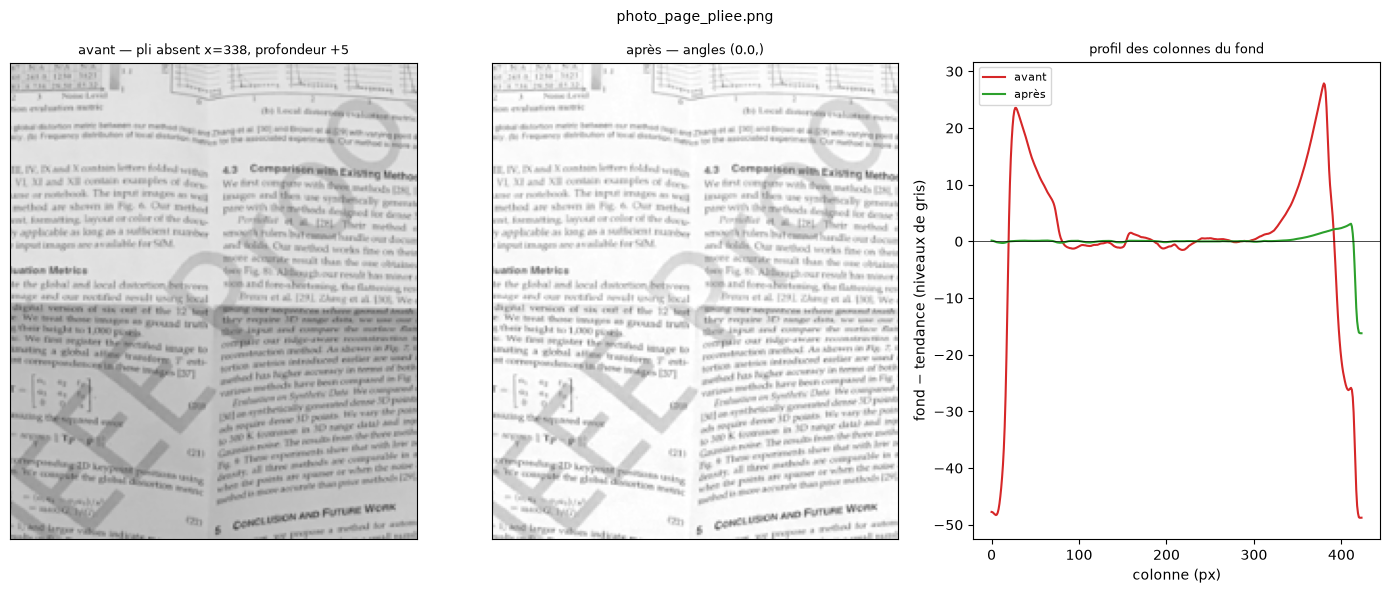

In [11]:
EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
images = sorted(p for p in SAMPLES.glob("*") if p.suffix.lower() in EXT and "_pre" not in p.stem
                and not p.stem.startswith(("worst_", "skew_")))
print(len(images), "image(s) dans", SAMPLES.relative_to(ROOT))
for path in images:
    gray = read_gray(path)
    r = preprocess_page(gray)
    print(path.name, gray.shape, r.fold, "angles", r.angles)
    h, w = gray.shape
    show(gray, r.image, r.fold, r.angles, path.name,
         crop=(slice(h // 4, 3 * h // 4), slice(w // 4, 3 * w // 4)))
    out = path.with_name(path.stem + "_pre.png")
    cv2.imwrite(str(out), r.image)
    print("  →", out.name)

Sur une vraie page pliée, deux choses à regarder : (1) la position du pli trouvée tombe-t-elle
bien sur la bande visible, ou sur une bordure de colonne (auquel cas la fenêtre de recherche
`search` ou le seuil `min_strength` sont à ajuster pour ce titre) ; (2) après correction, les
lignes de texte des deux moitiés sont-elles horizontales (`deskew_angle` sur chaque moitié doit
rendre ~0).

## 6. Photo d'une page pliée en 3D : dégauchissement appris (UVDoc)

Tout ce qui précède traite un journal **plié puis scanné à plat** : une ombre, deux inclinaisons.
Une **photo** d'une page pliée ou gondolée (ci-dessous, `data/samples/photo_page_pliee.png`) est un
autre problème : la surface est en 3D, toute la géométrie est déformée, et OpenCV seul ne fait
que gommer les ombres. Il faut un modèle appris. On branche **UVDoc** (Verhoeven, Magne &
Sorkine-Hornung, SIGGRAPH Asia 2023, licence MIT) : un réseau prédit une grille de 45 × 31 points
sur laquelle l'image est rééchantillonnée ; CPU, moins d'une seconde par page. **DocTr**
(Feng et al., 2021) fait la même chose avec un transformeur, mais sous licence *non commerciale* :
il peut remplacer UVDoc derrière la même interface (`dewarp_page`) si l'accord de l'auteur est
obtenu.

Extra `dewarp` (torch) ; les poids (32 Mo) sont téléchargés une fois dans `models/` et vérifiés par
empreinte. Sans torch, cette section s'affiche vide.

UVDoc : 0.40 s sur CPU pour 424×496 px ; puis prétraitement : pas de pli résiduel | angle (-0.1,)


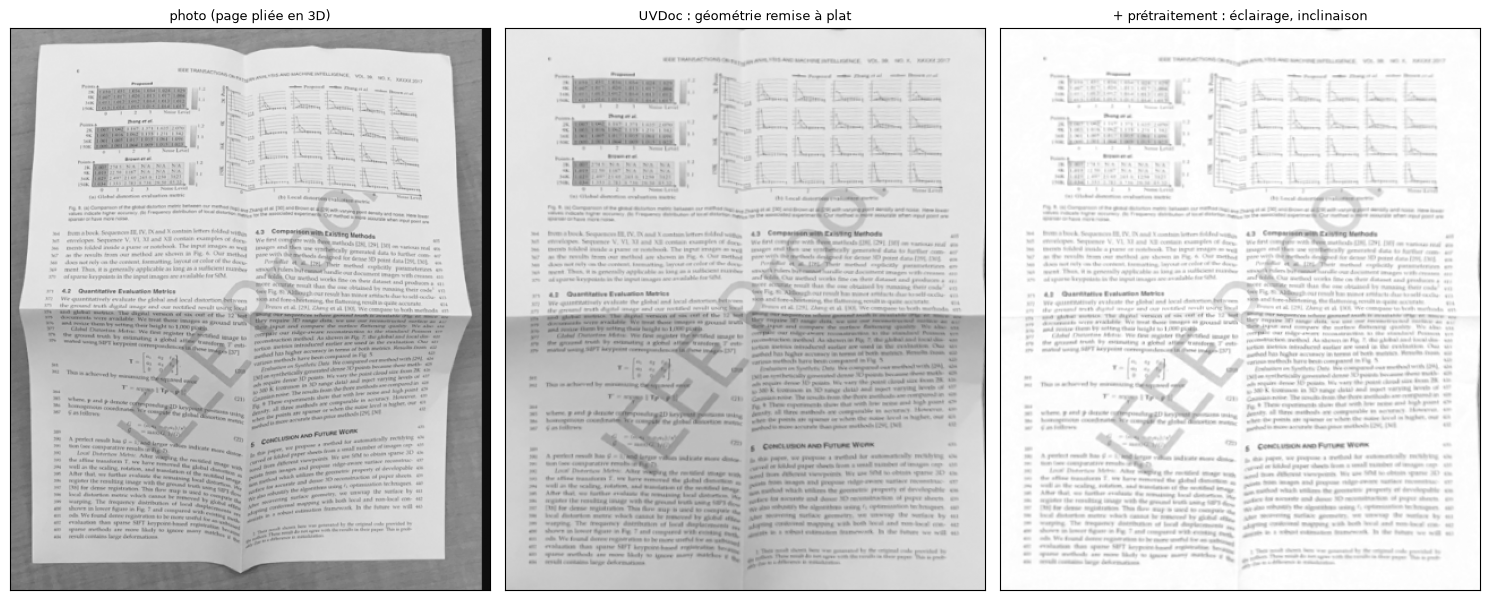

In [12]:
photo_path = SAMPLES / "photo_page_pliee.png"
try:
    import torch  # noqa: F401
    from finlam_prod.preprocess.dewarp import dewarp_page, fetch_weights, load_model
    HAVE_DEWARP = photo_path.is_file()
except ImportError:
    HAVE_DEWARP = False
    print("torch absent : pip install 'finlam-prod[dewarp]'")

if HAVE_DEWARP:
    import time
    model = load_model(fetch_weights(ROOT / "models"))
    photo = cv2.imread(str(photo_path), cv2.IMREAD_COLOR)
    t0 = time.perf_counter()
    flat = dewarp_page(photo, model)
    t1 = time.perf_counter()
    after = preprocess_page(flat)
    print(f"UVDoc : {t1 - t0:.2f} s sur CPU pour {photo.shape[1]}×{photo.shape[0]} px ;",
          "puis prétraitement :", after.fold.detected and "pli résiduel" or "pas de pli résiduel",
          "| angle", after.angles)
    fig, axes = plt.subplots(1, 3, figsize=(15, 6.5))
    for ax, img, title in zip(
        axes,
        (cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY), cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY),
         after.image),
        ("photo (page pliée en 3D)", "UVDoc : géométrie remise à plat",
         "+ prétraitement : éclairage, inclinaison"),
    ):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()

Lecture : UVDoc remet la page à plat (lignes droites, bords rectangulaires) mais ne touche pas à
l'éclairage — les ombres des plis restent ; c'est le prétraitement OpenCV qui les enlève ensuite.
Les deux sont complémentaires, dans cet ordre : géométrie, puis éclairage, puis pli résiduel et
inclinaison. Sur une page scannée à plat, UVDoc est inutile (et peut légèrement déformer) : on ne
l'appelle que pour des photos, ce que le QC peut décider sur la présence de bords de page non
rectangulaires.

## 7. Dans la chaîne : la tâche `preprocess`

Le prétraitement n'est pas une commande à part : c'est une **tâche du DAG** entre `fetch` et
`predict` (`dags/finlam_pipeline.py`), et `finlam-prod run` l'applique de la même façon
(`FINLAM_PREPROCESS=1` par défaut ; `FINLAM_DEWARP=1` ajoute UVDoc pour les photos).
`preprocess_issue` prend un fascicule, corrige chaque page qui a une image, fait pointer
`page.image_path` sur l'image corrigée, laisse passer les pages sans image, et écrit
`preprocess.json` : le résumé QC y lit le nombre de pages pliées ou inclinées.

Exemple sur un fascicule de trois vraies pages, dont deux avec un pli simulé :

In [13]:
import tempfile
from finlam_prod.data.schema import Issue, Page
from finlam_prod.preprocess.issue import REPORT_FILE, preprocess_issue

work = Path(tempfile.mkdtemp(prefix="finlam_demo_"))
pages = []
for i, path in enumerate(IMAGES[:3]):
    gray = read_gray(path)
    if i < 2:  # deux pages pliées, une page telle quelle
        angles = ((1.5, -1.0), (-2.0, 0.5))[i]
        gray = simulate_fold(gray, angles=angles, shadow_depth=60, seed=i).image
    image_path = work / f"f{i + 1}.jpg"
    cv2.imwrite(str(image_path), gray)
    pages.append(Page(id=path.stem[:8], issue_id="demo", index=i + 1,
                      width_px=gray.shape[1], height_px=gray.shape[0], image_path=str(image_path)))
pages.append(Page(id="sans-image", issue_id="demo", index=4))  # une page ALTO seule
issue = Issue(id="demo", name="démonstration", pages=pages)

corrected, report = preprocess_issue(issue, out_dir=work / "preprocessed")
report.write(work / REPORT_FILE)
print("résumé pour le QC :", report.summary)
pd.DataFrame([{k: v for k, v in vars(p).items() if k != "source"} for p in report.pages])

résumé pour le QC : {'preprocessed_pages': 3, 'skipped_pages': 1, 'folded_pages': 2, 'skewed_pages': 2, 'dewarped_pages': 0, 'preprocess_seconds': 2.53}


,page_id,index,output,fold_detected,fold_x,fold_depth,angles,dewarped,seconds,skipped
0,085ffb3a,1,/tmp/finlam_demo_sid1b0sp/preprocessed/f1_pre.png,True,874.0,-37.7,"[-0.9, 1.5]",False,0.921,NaN
1,17c1eb0c,2,/tmp/finlam_demo_sid1b0sp/preprocessed/f2_pre.png,True,885.0,-36.4,"[2.1, -0.1]",False,1.070,NaN
2,1e8d16df,3,/tmp/finlam_demo_sid1b0sp/preprocessed/f3_pre.png,False,NaN,NaN,[0.0],False,0.537,NaN
3,sans-image,4,NaN,False,NaN,NaN,[],False,0.000,pas d'image


Lecture : `folded_pages` et `skewed_pages` remontent dans `qc_summary.json` ; le routage du DAG
peut s'en servir (une page pliée dont le QC texte est faible part en relecture), et la
statistique de collection (part des pages pliées par titre) se calcule sur ces rapports.

- **Où** : tâche `preprocess` du DAG, après `fetch`, page par page, sans état partagé ;
  ~0,5 s par page CPU à 1 700 px de large, négligeable devant le modèle (1,66 s) ; UVDoc
  (~1 s CPU) seulement pour les photos, pas pour les scans à plat.
- **Quoi garder** : l'image corrigée pour les modèles (`input_pre.jsonl` pointe dessus,
  l'original reste en place), le rapport par page dans `preprocess.json`.
- **Ce qu'on ne fait pas** : inventer le texte caché dans le pli ; redresser une page pauvre en
  lignes de texte sur une estimation d'angle peu sûre (voir `row400`).

## 8. Le juge en aval : l'OCR avant / après

Tout ce qui précède mesure la géométrie (pli trouvé, lignes droites). Ce qui compte pour la BnF,
c'est ce que **l'OCR** lit en plus. Protocole : Tesseract (modèle `fra`) sur le tiers central de la
page (là où est le pli), et **rappel de mots** contre la transcription de référence du jeu
*La Liberté* (mots de 4 lettres et plus, multi-ensemble) — quatre conditions : scan d'origine,
origine après normalisation d'éclairage, page pliée (simulée), page corrigée. Le rappel absolu est
bas (Tesseract générique sur de la presse de 1925, sans entraînement), seul **l'écart entre
conditions** compte. Tesseract absent → section vide (`brew install tesseract tesseract-lang`
ou `apt install tesseract-ocr-fra`, et `pip install pytesseract`).

In [14]:
import os
import re
from collections import Counter

try:
    import pytesseract
    pytesseract.get_tesseract_version()
    LANGS = pytesseract.get_languages(config="")
    if "fra" not in LANGS and (ROOT / "data/tessdata/fra.traineddata").is_file():
        os.environ["TESSDATA_PREFIX"] = str(ROOT / "data/tessdata")
        LANGS = pytesseract.get_languages(config="")
    OCR_LANG = "fra" if "fra" in LANGS else "eng"
    HAVE_OCR = True
    print("Tesseract", pytesseract.get_tesseract_version(), "— langue", OCR_LANG)
except Exception as exc:  # noqa: BLE001
    HAVE_OCR = False
    print("Tesseract indisponible :", exc)

from finlam_prod.data.schema import load_pages

def _gt_pages():
    for name in ("la_liberte_test.jsonl", "la_liberte_test_n40.jsonl"):
        path = ROOT / "data/cache" / name
        if path.is_file():
            return {p.id: p for p in load_pages(path)}
    return {}

GT = _gt_pages() if HAVE_OCR else {}
print(len(GT), "pages avec transcription de référence")


def words(text):
    return Counter(t for t in re.findall(r"[a-zàâçéèêëîïôûùüÿœ'-]+", text.lower()) if len(t) >= 4)


def ocr(img):
    return pytesseract.image_to_string(img, lang=OCR_LANG, config="--psm 3")


def recall(reference, text):
    got = words(text)
    return sum((reference & got).values()) / max(1, sum(reference.values()))

Tesseract 5.3.4 — langue fra
40 pages avec transcription de référence


In [15]:
N_PAGES = 6  # ~30 s d'OCR par condition et par page
rows = []
if HAVE_OCR and GT:
    for i, path in enumerate([p for p in IMAGES if p.stem in GT][:N_PAGES]):
        page_gt = GT[path.stem]
        gray = read_gray(path)
        h, w = gray.shape
        crop = (slice(0, h), slice(w // 3, 2 * w // 3))
        # référence : les zones dont le centre tombe dans le tiers central
        centre_zones = []
        for z in page_gt.zones:
            xs = [pt[0] for pt in z.polygon]
            cx = (min(xs) + max(xs)) / 2
            scale = 100 if max(xs) <= 100 else w
            if scale / 3 <= cx <= 2 * scale / 3:
                centre_zones.append(z.text or "")
        reference = words(" ".join(centre_zones))
        angles = ((1.5, -1.0), (-2.0, 0.5), (0.8, 1.6))[i % 3]
        folded = simulate_fold(gray, angles=angles, shadow_depth=60, seed=i)
        fixed = preprocess_page(folded.image)
        conditions = {
            "origine": gray,
            "origine normalisée": normalise_illumination(gray),
            "pliée": folded.image,
            "corrigée": fixed.image,
        }
        row = {"page": path.stem[:8], "mots référence": sum(reference.values())}
        for name, img in conditions.items():
            row[name] = round(recall(reference, ocr(img[crop])), 3)
        rows.append(row)
        print(row)
ocr_table = pd.DataFrame(rows)
if len(ocr_table):
    means = ocr_table[["origine", "origine normalisée", "pliée", "corrigée"]].mean()
    print("rappel moyen :", means.round(3).to_dict())
    cost = 100 * (means["pliée"] - means["origine"])
    gain = 100 * (means["corrigée"] - means["pliée"])
    flat = 100 * (means["origine normalisée"] - means["origine"])
    print(f"coût du pli : {cost:+.1f} points ; récupéré par la correction : {gain:+.1f} points ;",
          f"normalisation seule sur page propre : {flat:+.1f} points")
ocr_table

{'page': '085ffb3a', 'mots référence': 1526, 'origine': 0.467, 'origine normalisée': 0.488, 'pliée': 0.324, 'corrigée': 0.398}


{'page': '17c1eb0c', 'mots référence': 852, 'origine': 0.208, 'origine normalisée': 0.285, 'pliée': 0.014, 'corrigée': 0.019}


{'page': '1e8d16df', 'mots référence': 937, 'origine': 0.592, 'origine normalisée': 0.632, 'pliée': 0.449, 'corrigée': 0.395}


{'page': '28d0b5d8', 'mots référence': 992, 'origine': 0.422, 'origine normalisée': 0.364, 'pliée': 0.192, 'corrigée': 0.277}


{'page': '352cb719', 'mots référence': 1268, 'origine': 0.468, 'origine normalisée': 0.45, 'pliée': 0.267, 'corrigée': 0.383}


{'page': '37214212', 'mots référence': 1557, 'origine': 0.333, 'origine normalisée': 0.461, 'pliée': 0.297, 'corrigée': 0.382}
rappel moyen : {'origine': 0.415, 'origine normalisée': 0.447, 'pliée': 0.257, 'corrigée': 0.309}
coût du pli : -15.8 points ; récupéré par la correction : +5.2 points ; normalisation seule sur page propre : +3.2 points


,page,mots référence,origine,origine normalisée,pliée,corrigée
0,085ffb3a,1526,0.467,0.488,0.324,0.398
1,17c1eb0c,852,0.208,0.285,0.014,0.019
2,1e8d16df,937,0.592,0.632,0.449,0.395
3,28d0b5d8,992,0.422,0.364,0.192,0.277
4,352cb719,1268,0.468,0.450,0.267,0.383
5,37214212,1557,0.333,0.461,0.297,0.382


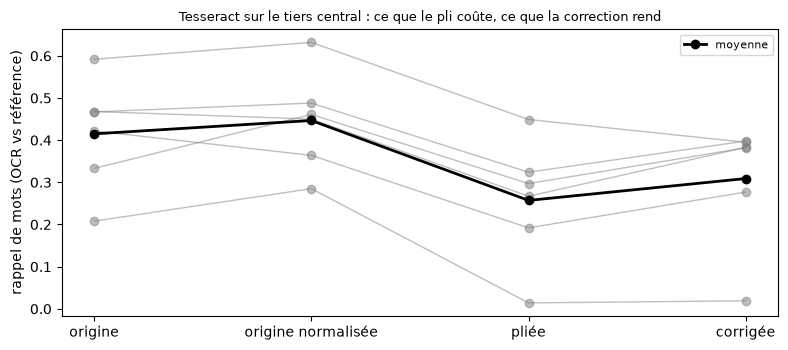

In [16]:
if len(ocr_table):
    fig, ax = plt.subplots(figsize=(8, 3.6))
    cols = ["origine", "origine normalisée", "pliée", "corrigée"]
    for _, r in ocr_table.iterrows():
        ax.plot(cols, [r[c] for c in cols], marker="o", color="tab:gray", alpha=0.5, linewidth=1)
    ax.plot(cols, [ocr_table[c].mean() for c in cols], marker="o", color="black", linewidth=2,
            label="moyenne")
    ax.set_ylabel("rappel de mots (OCR vs référence)")
    ax.set_title("Tesseract sur le tiers central : ce que le pli coûte, ce que la correction rend",
                 fontsize=9)
    ax.legend(fontsize=8); fig.tight_layout()

Lecture, sans embellir : sur six pages, le pli (ombre + deux inclinaisons) coûte **−16 points**
de rappel ; la correction en rend **+5** — un tiers, pas tout — et sur une page (`1e8d16df`) l'OCR
corrigé est même un peu moins bon que le plié : la segmentation de page de Tesseract (`--psm 3`)
réagit à de petits changements de l'image, ce qui ajoute du bruit à la mesure. Ce qui n'est pas
récupéré tient au texte écrasé dans la bande du pli (la division par le fond restaure le
contraste, pas le détail perdu) et à l'interpolation du rééchantillonnage. La **normalisation
d'éclairage seule**, sur une page propre, rend **+3 points** : elle peut rester active par
défaut. Conclusion pour la chaîne : la tâche `preprocess` se justifie (elle rend des points, n'en
coûte pas), mais le chiffre qui compte est à refaire avec l'OCR de production de la BnF, sur plus
de pages, et sur de vraies pages pliées quand on en aura — et c'est ce protocole-là (référence =
transcription du jeu, quatre conditions, rappel de mots) qu'il faut garder.